<a href="https://colab.research.google.com/github/gguex/ISH_ressources_cours_ML/blob/main/TP04_arbres_forets.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine Learning (Lettres) TP 4 : Arbres de décision et forêts aléatoires

Dans ce TP, nous allons :

1. Construire et lire des **arbres de décision** sur le jeu de données du Titanic, comme dans le cours.
2. Comparer les **frontières de décision** d'un arbre et d'une forêt sur les iris.
3. Comparer une **régression logistique et une forêt aléatoire** sur le Titanic complet, avec un prétraitement adapté à chaque type de variable, puis **sauvegarder** la pipeline retenue.

Un exercice consistera à refaire cette comparaison sur un nouveau jeu de données.

Les nouveautés sont les deux modèles à base d'arbres (`DecisionTreeClassifier`, `RandomForestClassifier`), la fonction `plot_tree` pour dessiner un arbre, et surtout le `ColumnTransformer`, qui permet d'appliquer un prétraitement différent aux variables numériques et catégorielles. Tout le reste a déjà été vu.

In [5]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
# Les modèles
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
# Pour séparer le jeu de données et chercher les hyperparamètres
from sklearn.model_selection import train_test_split, GridSearchCV
# Les prétraitements, et de quoi les enchaîner avec un modèle
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
# Nos différentes mesures
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Le même style de graphiques qu'aux TP précédents
sns.set_theme(style="whitegrid", palette="colorblind")

In [6]:
# Connexion à Google Drive sur Colab ; dossier local sinon
try:
    from google.colab import drive
except ImportError:
    data_path = Path("data") / "TP4"
else:
    drive.mount("/content/drive")
    data_path = Path("/content/drive/MyDrive/Colab Notebooks/data/TP4")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Nous reprenons la fonction `compute_scores` du TP 3 :

In [7]:
def compute_scores(outputs_true, outputs_pred, average="binary"):
    return {
        "Exactitude": accuracy_score(outputs_true, outputs_pred),
        "Précision": precision_score(outputs_true, outputs_pred, average=average, zero_division=0),
        "Rappel": recall_score(outputs_true, outputs_pred, average=average),
        "F1": f1_score(outputs_true, outputs_pred, average=average),
    }

---

## 1. Arbres de décision sur le Titanic

Le jeu de données "titanic.csv" (https://www.kaggle.com/c/titanic/data) décrit les passagers du Titanic : classe (**Pclass**), genre (**Sex**), âge (**Age**), nombre de frères, sœurs et conjoints à bord (**SibSp**), de parents et enfants à bord (**Parch**), prix du billet (**Fare**), port d'embarquement (**Embarked**), et surtout s'ils ont survécu (**Survived**, 1 = oui). C'est la variable que nous allons prédire.

In [8]:
file_path = data_path / "titanic.csv"
data = pd.read_csv(file_path)
data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Certaines variables ont des valeurs manquantes :

In [9]:
missing = data.isna().sum()
missing[missing > 0]

,0
Age,177
Cabin,687
Embarked,2


Pour commencer, nous construisons un arbre à partir de l'âge et du genre seulement, comme dans le cours. Pour cette première partie, on enlève simplement les passagers dont l'âge est inconnu, et on encode le genre en une variable binaire avec `pd.get_dummies` (vu au TP 3). Avec `drop_first=True`, on ne garde qu'une colonne, `Sex_male`.

In [10]:
data_age = data.dropna(subset=["Age"])
inputs = pd.get_dummies(data_age[["Age", "Sex"]], drop_first=True)
outputs = data_age["Survived"]
inputs.head()

,Age,Sex_male
0,22.0,True
1,38.0,False
2,26.0,False
3,35.0,False
4,35.0,True


La classe `DecisionTreeClassifier` construit un arbre de classification. Sans contrainte, l'arbre continue à séparer les individus jusqu'à ce que toutes les feuilles soient pures :

In [11]:
classif_tree = DecisionTreeClassifier(random_state=42)
classif_tree.fit(inputs, outputs)
print(f"Profondeur : {classif_tree.get_depth()}, nombre de feuilles : {classif_tree.get_n_leaves()}")

Profondeur : 18, nombre de feuilles : 111


Un tel arbre est illisible et sûrement en surapprentissage. On le reconstruit en l'**élaguant** : le paramètre `ccp_alpha` est le $\alpha$ du cours, qui pénalise le nombre de feuilles. La fonction `plot_tree` dessine l'arbre obtenu. Dans chaque nœud, on lit la condition de séparation, l'indice de Gini, le nombre d'individus, leur répartition entre les classes (`value`) et la classe majoritaire.

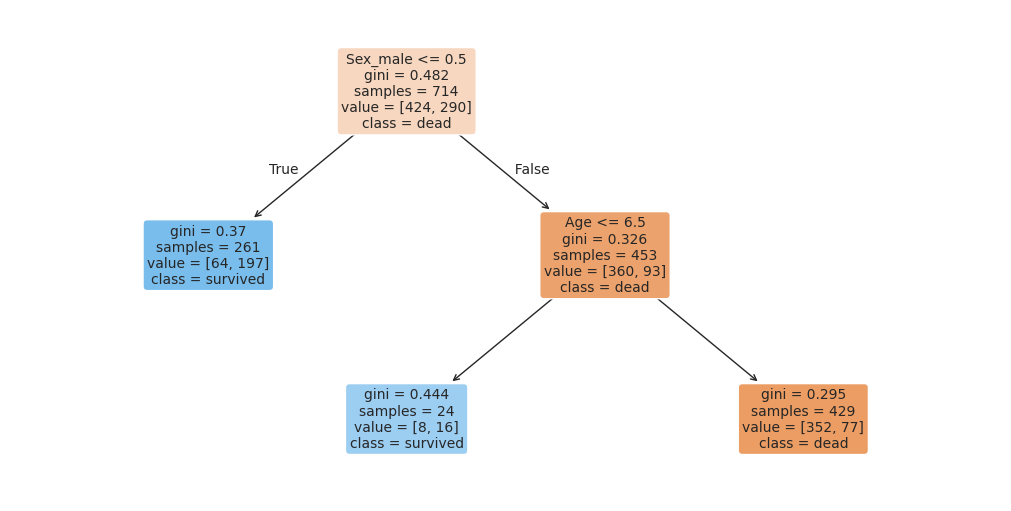

In [12]:
classif_tree_pruned = DecisionTreeClassifier(ccp_alpha=0.005, random_state=42)
classif_tree_pruned.fit(inputs, outputs)

fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
plot_tree(classif_tree_pruned, feature_names=inputs.columns, class_names=["dead", "survived"],
          filled=True, rounded=True, fontsize=10, ax=ax)
plt.show()

L'arbre se lit de haut en bas : la racine sépare d'abord les hommes des femmes, puis l'âge intervient. Essayez d'autres valeurs de `ccp_alpha` (par exemple 0.002 et 0.02) pour voir l'arbre grandir ou rétrécir.

Remarquez que cet arbre a été construit sur toutes les données, pour l'illustration : il n'est pas évalué ici.

---

## 2. Frontières de décision : arbre contre forêt

On va maintenant faire des arbres et des forêts sur les iris de Fisher (et oui, encore), avec deux variables seulement, la longueur et la largeur des sépales, afin de tracer les frontières de décision.

In [13]:
file_path = data_path / "iris.csv"
data = pd.read_csv(file_path)
inputs = data[["sepal.length", "sepal.width"]]
outputs = data["variety"]
classes = sorted(outputs.unique())

Un arbre élagué sur ces deux variables donne :

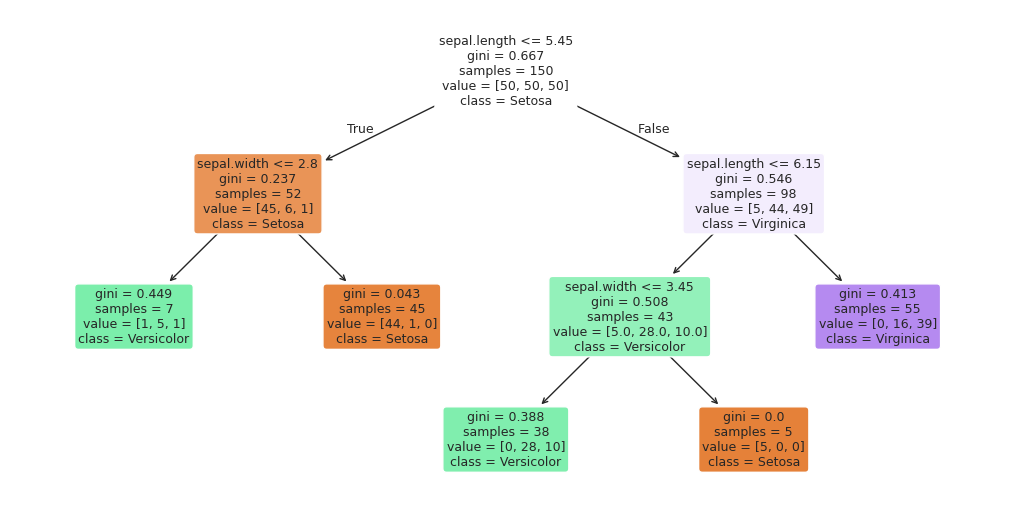

In [14]:
classif_tree = DecisionTreeClassifier(ccp_alpha=0.02, random_state=42)
classif_tree.fit(inputs, outputs)

fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
plot_tree(classif_tree, feature_names=inputs.columns, class_names=classes,
          filled=True, rounded=True, fontsize=9, ax=ax)
plt.show()

Pour tracer les zones de décision, on reprend la méthode du TP 3 : une grille de points construite avec `pd.merge(..., how="cross")`, la prédiction du modèle en chaque point, puis deux nuages de points superposés. Comme nous allons le faire pour deux modèles, on en fait une fonction.

In [15]:
def plot_zones(model, title):
    # Une grille sur les deux variables
    sepal_length = pd.DataFrame({"sepal.length": np.linspace(data["sepal.length"].min(),
                                                              data["sepal.length"].max(), 100)})
    sepal_width = pd.DataFrame({"sepal.width": np.linspace(data["sepal.width"].min(),
                                                            data["sepal.width"].max(), 100)})
    grid = pd.merge(sepal_length, sepal_width, how="cross")
    grid["prediction"] = model.predict(grid)
    # Les zones, puis les fleurs
    fig, ax = plt.subplots(figsize=(7, 5), layout="constrained")
    sns.scatterplot(data=grid, x="sepal.length", y="sepal.width",
                    hue="prediction", hue_order=classes,
                    marker="s", s=12, alpha=0.3, linewidth=0, legend=False, ax=ax)
    sns.scatterplot(data=data, x="sepal.length", y="sepal.width",
                    hue="variety", hue_order=classes, style="variety", ax=ax)
    ax.set(xlabel="Longueur du sépale (cm)", ylabel="Largeur du sépale (cm)", title=title)
    ax.legend(title="Espèce")
    plt.show()

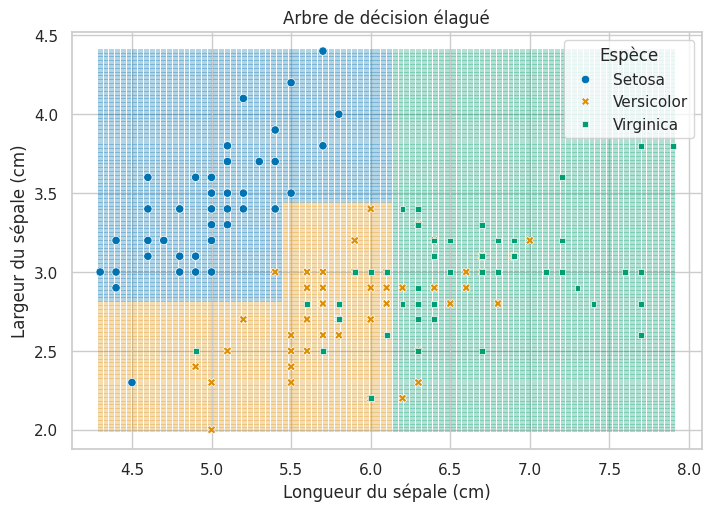

In [16]:
plot_zones(classif_tree, "Arbre de décision élagué")

Les frontières d'un arbre sont des segments parallèles aux axes : chaque nœud coupe l'espace selon une seule variable.

Comparons avec une **forêt aléatoire**. On en fait une toute petite (9 arbres de profondeur 2) pour pouvoir regarder ses arbres. Comme il n'y a que deux variables, chaque séparation n'en tire qu'une au hasard (`max_features=1`).

In [17]:
classif_forest = RandomForestClassifier(n_estimators=9, max_depth=2, max_features=1, random_state=42)
classif_forest.fit(inputs, outputs)

RandomForestClassifier(max_depth=2, max_features=1, n_estimators=9,
                       random_state=42)

Les arbres de la forêt sont stockés dans l'attribut `estimators_`. Chacun a été entraîné sur un échantillon bootstrap différent ; en voici un (changez l'indice pour en voir d'autres) :

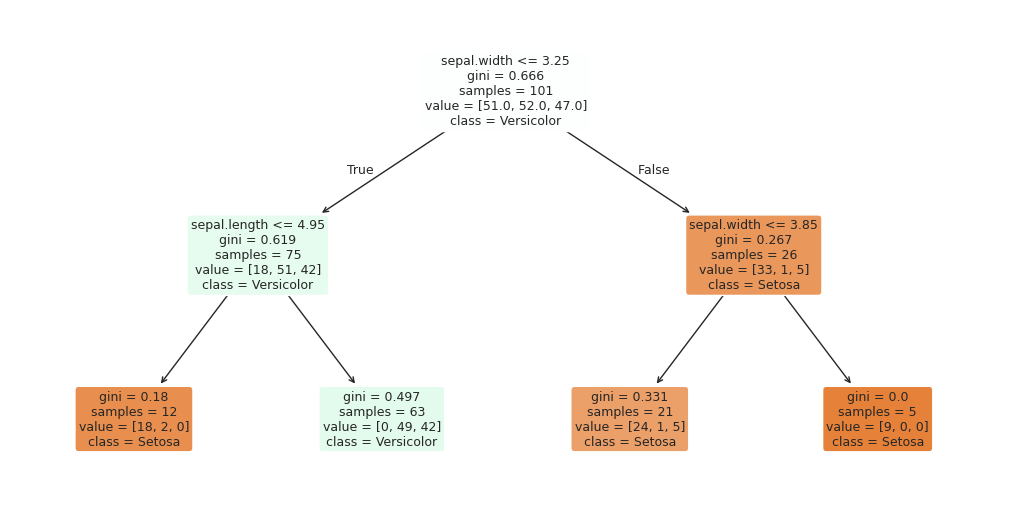

In [18]:
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
plot_tree(classif_forest.estimators_[0], feature_names=inputs.columns, class_names=classes,
          filled=True, rounded=True, fontsize=9, ax=ax)
plt.show()

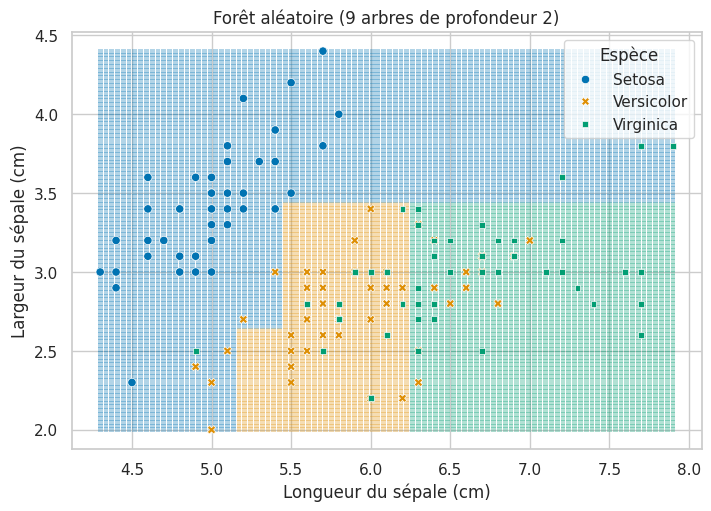

In [19]:
plot_zones(classif_forest, "Forêt aléatoire (9 arbres de profondeur 2)")

En combinant les votes de ses arbres, la forêt obtient des frontières plus souples que chaque arbre pris séparément. Ces deux modèles ont été entraînés sur toutes les fleurs : on ne peut rien dire ici de leur généralisation.

---

## 3. Régression logistique contre forêt aléatoire sur le Titanic

Revenons au Titanic, cette fois avec toutes les variables utiles. Elles sont de deux types :

* des variables **numériques** : l'âge, les nombres de proches à bord et le prix du billet ;
* des variables **catégorielles** : la classe, le genre et le port d'embarquement.

Chaque type demande son propre prétraitement. Les numériques ont besoin d'une imputation (l'âge manque souvent) et d'une standardisation pour la régression logistique. Les catégorielles doivent être encodées en one-hot, après imputation de la modalité la plus fréquente pour les deux ports manquants.

In [20]:
file_path = data_path / "titanic.csv"
data = pd.read_csv(file_path)

numeric_columns = ["Age", "SibSp", "Parch", "Fare"]
categorical_columns = ["Pclass", "Sex", "Embarked"]

inputs = data[numeric_columns + categorical_columns]
outputs = data["Survived"]
outputs.value_counts(normalize=True)

,proportion
Survived,
0,0.616162
1,0.383838


On sépare le jeu de données comme d'habitude, en stratifiant selon la survie :

In [21]:
inputs_dev, inputs_test, outputs_dev, outputs_test = \
    train_test_split(inputs, outputs, test_size=0.2, stratify=outputs, random_state=42)

### Un prétraitement par type de variable : `ColumnTransformer`

Jusqu'ici, nos pipelines appliquaient les mêmes étapes à toutes les colonnes. Le `ColumnTransformer` permet d'appliquer **une pipeline différente à chaque groupe de colonnes**, puis de recoller les résultats côte à côte. On lui donne une liste de triplets : un nom, une pipeline, et la liste des colonnes concernées.

Pour les catégorielles, `OneHotEncoder` fait le même travail que `pd.get_dummies`, mais à l'intérieur de la pipeline : il apprend les modalités sur les données d'entraînement, et l'option `handle_unknown="ignore"` évite une erreur si une modalité inconnue apparaît dans de nouvelles données.

In [22]:
numeric_pipeline = make_pipeline(SimpleImputer(strategy="mean"),
                                 StandardScaler())
categorical_pipeline = make_pipeline(SimpleImputer(strategy="most_frequent"),
                                     OneHotEncoder(handle_unknown="ignore", sparse_output=False))

preprocessing = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns),
])
preprocessing

ColumnTransformer(transformers=[('numeric',
                                 Pipeline(steps=[('simpleimputer',
                                                  SimpleImputer()),
                                                 ('standardscaler',
                                                  StandardScaler())]),
                                 ['Age', 'SibSp', 'Parch', 'Fare']),
                                ('categorical',
                                 Pipeline(steps=[('simpleimputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehotencoder',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['Pclass', 'Sex', 'Embarked'])])

Le `ColumnTransformer` s'utilise comme n'importe quelle étape de prétraitement : `fit` apprend les moyennes, écarts-types et modalités sur le jeu de développement, `transform` les applique. Regardons ce qu'il produit (`get_feature_names_out` donne le nom des colonnes créées) :

In [23]:
preprocessing.fit(inputs_dev)
pd.DataFrame(preprocessing.transform(inputs_dev),
             columns=preprocessing.get_feature_names_out()).head()

,numeric__Age,numeric__SibSp,numeric__Parch,numeric__Fare,categorical__Pclass_1,categorical__Pclass_2,categorical__Pclass_3,categorical__Sex_female,categorical__Sex_male,categorical__Embarked_C,categorical__Embarked_Q,categorical__Embarked_S
0,-5.463229e-16,-0.465084,-0.466183,0.513812,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
1,-5.463229e-16,-0.465084,-0.466183,-0.662563,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
2,-5.463229e-16,-0.465084,-0.466183,3.955399,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
3,-9.078708e-01,-0.465084,0.727782,-0.467874,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0
4,9.167471e-02,0.478335,0.727782,-0.115977,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0


Les variables numériques sont standardisées, et chaque variable catégorielle est devenue une colonne par modalité. Ce prétraitement sera la première étape de nos deux pipelines. Il sera réajusté sur chaque pli lors de la cross-validation, comme au TP 2.

### La référence naïve

In [24]:
majority_class = outputs_dev.mode()[0]
outputs_naive_test = np.full(len(outputs_test), majority_class)

### La régression logistique

La mesure retenue est le F1 de la classe "survécu", qui tient compte à la fois des survivants manqués et des survivants prédits à tort. Comme au TP 3, on cherche `C` par cross-validation. Avec `cv=k`, les plis stratifiés sont les mêmes pour tous les modèles de ce TP, ce qui rend la comparaison équitable.

In [25]:
k = 5
params_C = np.linspace(0.01, 2, 40)
logistic_pipeline = make_pipeline(preprocessing,
                                  LogisticRegression())
grid_search_logistic = GridSearchCV(logistic_pipeline,
                                    {"logisticregression__C": params_C},
                                    cv=k,
                                    scoring="f1")
grid_search_logistic.fit(inputs_dev, outputs_dev)
print(grid_search_logistic.best_params_)
print(f"F1 de validation : {grid_search_logistic.best_score_:.2%}")

{'logisticregression__C': np.float64(1.5917948717948718)}
F1 de validation : 72.55%


### La forêt aléatoire

Pour la forêt, on fixe le nombre d'arbres à 200 et on règle la complexité des arbres avec `min_samples_leaf`, le nombre minimal d'individus dans une feuille : plus il est grand, plus les arbres sont courts. La standardisation est inutile pour les arbres, mais elle ne gêne pas : on garde le même prétraitement, ce qui simplifie la comparaison. `random_state` fixe le tirage des échantillons bootstrap et des variables.

In [26]:
params_leaf = [1, 2, 5, 10, 20, 50]
forest_pipeline = make_pipeline(preprocessing,
                                RandomForestClassifier(n_estimators=200, random_state=42))
grid_search_forest = GridSearchCV(forest_pipeline,
                                  {"randomforestclassifier__min_samples_leaf": params_leaf},
                                  cv=k,
                                  scoring="f1")
grid_search_forest.fit(inputs_dev, outputs_dev)
print(grid_search_forest.best_params_)
print(f"F1 de validation : {grid_search_forest.best_score_:.2%}")

{'randomforestclassifier__min_samples_leaf': 2}
F1 de validation : 75.40%


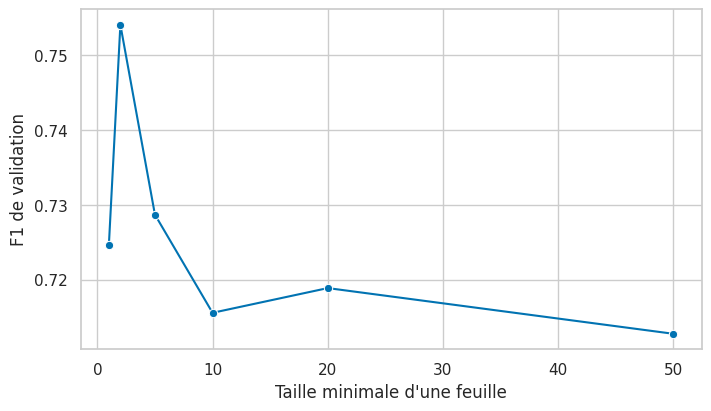

In [27]:
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
sns.lineplot(x=params_leaf, y=grid_search_forest.cv_results_["mean_test_score"], marker="o", ax=ax)
ax.set(xlabel="Taille minimale d'une feuille", ylabel="F1 de validation")
plt.show()

### Comparaison

Les F1 de validation des deux modèles sont proches. Pour se faire une idée de la variabilité, on peut regarder l'écart-type du F1 entre les plis (`std_test_score`) pour le meilleur réglage de chaque modèle :

In [28]:
print(f"Logistique : écart-type entre plis = "
      f"{grid_search_logistic.cv_results_['std_test_score'][grid_search_logistic.best_index_]:.2%}")
print(f"Forêt : écart-type entre plis = "
      f"{grid_search_forest.cv_results_['std_test_score'][grid_search_forest.best_index_]:.2%}")

Logistique : écart-type entre plis = 4.08%
Forêt : écart-type entre plis = 5.72%


L'écart entre les deux modèles est du même ordre que la variabilité entre plis : on ne peut pas affirmer que l'un est meilleur. Voici leurs mesures sur le jeu de test, regardé une seule fois :

In [29]:
best_logistic = grid_search_logistic.best_estimator_
best_forest = grid_search_forest.best_estimator_

outputs_logistic_test = best_logistic.predict(inputs_test)
outputs_forest_test = best_forest.predict(inputs_test)

test_scores = pd.DataFrame({
    "Référence naïve": compute_scores(outputs_test, outputs_naive_test),
    "Régression logistique": compute_scores(outputs_test, outputs_logistic_test),
    "Forêt aléatoire": compute_scores(outputs_test, outputs_forest_test),
}).T
test_scores.round(3)

,Exactitude,Précision,Rappel,F1
Référence naïve,0.615,0.000,0.000,0.000
Régression logistique,0.799,0.789,0.652,0.714
Forêt aléatoire,0.804,0.815,0.638,0.715


### Quelles variables comptent ?

Les deux modèles ne s'interprètent pas de la même manière. La régression logistique donne un **coefficient** par colonne, dont le signe indique le sens de l'effet (les variables étant standardisées, les tailles sont comparables). La forêt donne une **importance** par colonne (`feature_importances_`), toujours positive : elle dit quelles variables servent à séparer, pas dans quel sens.

Dans une pipeline, `[0]` est la première étape (notre `ColumnTransformer`, qui connaît le nom des colonnes créées) et `[-1]` la dernière (le modèle).

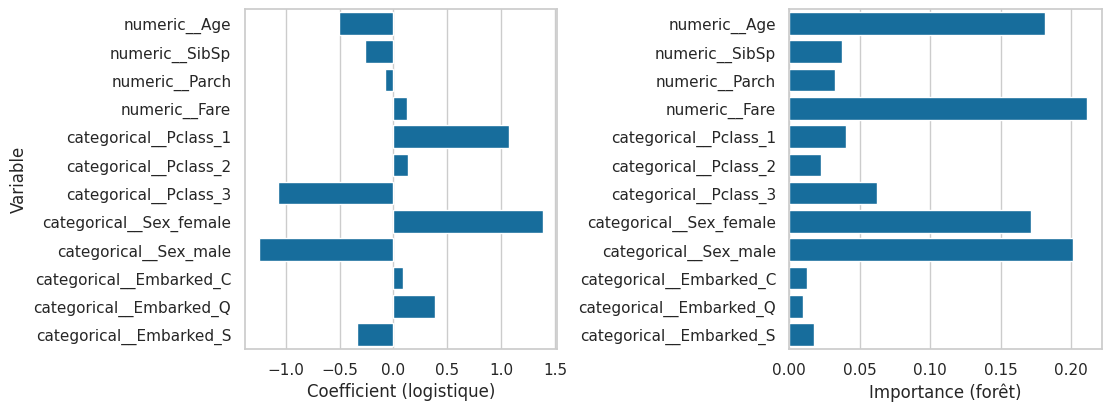

In [30]:
feature_names = best_forest[0].get_feature_names_out()
importances = pd.DataFrame({
    "Variable": feature_names,
    "Coefficient (logistique)": best_logistic[-1].coef_[0],
    "Importance (forêt)": best_forest[-1].feature_importances_,
}).set_index("Variable")

fig, axs = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
sns.barplot(x=importances["Coefficient (logistique)"], y=importances.index, ax=axs[0])
sns.barplot(x=importances["Importance (forêt)"], y=importances.index, ax=axs[1])
axs[1].set(ylabel="")
plt.show()

Le genre, le prix du billet, l'âge et la troisième classe dominent dans les deux modèles. La logistique ajoute le sens : être une femme augmente la probabilité de survie, être en troisième classe ou plus âgé la diminue.

### Sauvegarder et recharger la pipeline

Pour réutiliser un modèle sans le réentraîner (dans un autre notebook, ou pour le rendu), on sauvegarde la **pipeline entière** avec `joblib`. Comme elle contient le prétraitement, elle accepte directement des données brutes, avec leurs valeurs manquantes et leurs variables catégorielles.

In [31]:
model_path = data_path / "foret_titanic.joblib"
joblib.dump(best_forest, model_path)

loaded_forest = joblib.load(model_path)
print(f"Mêmes prédictions après rechargement : "
      f"{np.array_equal(loaded_forest.predict(inputs_test), outputs_forest_test)}")

Mêmes prédictions après rechargement : True


Le modèle rechargé peut prédire la survie d'un passager imaginaire, décrit avec les colonnes d'origine :

In [32]:
new_passenger = pd.DataFrame({"Age": [30], "SibSp": [0], "Parch": [0], "Fare": [20],
                              "Pclass": [2], "Sex": ["female"], "Embarked": ["S"]})
print(f"Prédiction : {loaded_forest.predict(new_passenger)[0]}")
print(f"Probabilité de survie : {loaded_forest.predict_proba(new_passenger)[0, 1]:.2%}")

Prédiction : 1
Probabilité de survie : 95.19%


Changez le genre ou la classe de ce passager pour voir la probabilité évoluer.

---

## Exercice

Dans cet exercice, vous allez utiliser le jeu de données "contraceptive.tsv" (https://www.kaggle.com/datasets/faizunnabi/contraceptive-method-choice), qui donne des variables socio-économiques pour 1473 femmes indonésiennes, ainsi que leur méthode de contraception (variable **target** : 1 = aucune, 2 = méthode de long terme, 3 = méthode de court terme). Le but est de prédire cette méthode à partir des autres variables.

Les variables d'éducation et de niveau de vie sont ordinales (1 à 4) et peuvent être traitées comme numériques ; les variables binaires aussi. En revanche, **Husband_occupation** est une catégorie sans ordre : elle doit être encodée en one-hot. Il vous faut :

1. Charger les données (le séparateur est une tabulation : `sep="\t"`) et séparer en jeux de développement et de test.
2. Construire un `ColumnTransformer` adapté : standardisation pour les numériques, one-hot pour `Husband_occupation`.
3. Faire une régression logistique régularisée et une forêt aléatoire, avec une recherche de `C` et de `min_samples_leaf` par cross-validation. La mesure est le **F1 macro**, puisqu'il y a trois classes.
4. Comparer les deux modèles sur la validation, puis calculer leurs mesures sur le jeu de test, avec la référence naïve. Afficher la matrice de confusion du meilleur modèle (reprenez `plot_confusion` du TP 3).
5. Afficher l'importance des variables de la forêt. Quelles variables comptent ?
6. Sauvegarder la pipeline retenue et vérifier son rechargement.

Reprenez le code de la troisième partie : il ne s'agit pas de tout réécrire. Bonne chance !

In [33]:
file_path = data_path / "contraceptive.tsv"
data = pd.read_csv(file_path, sep="\t")
data.head()

,Wife_age,Wife_education,Husband_education,Children,Wife_religion,Wife_working,Husband_occupation,Standard-of-living,Media_exposure,target
0,24,2,3,3,1,1,2,3,0,1
1,45,1,3,10,1,1,3,4,0,1
2,43,2,3,7,1,1,3,4,0,1
3,42,3,2,9,1,1,3,3,0,1
4,36,3,3,8,1,1,3,2,0,1
